In [1]:
import sys
import json
from pathlib import Path

_root = next(p for p in Path.cwd().resolve().parents if (p / '.git').exists() or (p / 'setup.py').exists())
for _p in (str(_root), str(_root / 'src')):
    if _p not in sys.path:
        sys.path.insert(0, _p)

from metab_processing.LinearRegression import signature_helpers as sh, signature_batch as sb
from metab_processing.LinearRegression.signature_configs import CONFIGS

cfg = CONFIGS['breast']

# Which ratio plots `view()` renders (keys of sh.plot_res).
PLOTS = ('ratio', 'variance_ratio', 'meansq_variance_ratio')

In [2]:
membership = json.load(open(Path(cfg.cache_dir) / '_membership.json'))
print(f'{cfg.name}: loaded membership for {len(membership)} gene set(s)')

breast: loaded membership for 34 gene set(s)


## breast: target signatures -- membership, missing, present, factor-removed, remaining

In [3]:
print(f'===== {cfg.name} target signatures: membership + factor-removal =====')
for name in list(cfg.target_signatures) + list(cfg.neg_controls) + list(cfg.manual_sets):
    m = membership.get(name, {})
    print(f'\n{name}')
    print(f"  present ({len(m.get('present', []))}): {m.get('present', [])}")
    print(f"  missing ({len(m.get('missing', []))}): {m.get('missing', [])}")
    print(f"  total: {m.get('total', 0)}")
    print(f"  factor_removed ({len(m.get('factor_removed', []))}): {m.get('factor_removed', [])}")
    print(f"  remaining ({len(m.get('remaining', []))}): {m.get('remaining', [])}")

===== breast target signatures: membership + factor-removal =====

HALLMARK_IL2_STAT5_SIGNALING
  present (199): ['ABCB1', 'ADAM19', 'AGER', 'AHCY', 'AHNAK', 'AHR', 'ALCAM', 'AMACR', 'ANXA4', 'APLP1', 'ARL4A', 'BATF', 'BATF3', 'BCL2', 'BCL2L1', 'BHLHE40', 'BMP2', 'BMPR2', 'CA2', 'CAPG', 'CAPN3', 'CASP3', 'CCND2', 'CCND3', 'CCNE1', 'CCR4', 'CD44', 'CD48', 'CD79B', 'CD81', 'CD83', 'CD86', 'CDC42SE2', 'CDC6', 'CDCP1', 'CDKN1C', 'CISH', 'CKAP4', 'COCH', 'COL6A1', 'CSF1', 'CSF2', 'CST7', 'CTLA4', 'CTSZ', 'CXCL10', 'CYFIP1', 'DCPS', 'DENND5A', 'DHRS3', 'DRC1', 'ECM1', 'EEF1AKMT1', 'EMP1', 'ENO3', 'ENPP1', 'EOMES', 'ETFBKMT', 'ETV4', 'F2RL2', 'FAH', 'FGL2', 'FLT3LG', 'FURIN', 'GABARAPL1', 'GADD45B', 'GALM', 'GATA1', 'GBP4', 'GLIPR2', 'GPR65', 'GPR83', 'GPX4', 'GSTO1', 'GUCY1B1', 'HIPK2', 'HK2', 'HOPX', 'HUWE1', 'HYCC2', 'ICOS', 'IFITM3', 'IFNGR1', 'IGF1R', 'IGF2R', 'IKZF2', 'IKZF4', 'IL10', 'IL10RA', 'IL13', 'IL18R1', 'IL1R2', 'IL1RL1', 'IL2RA', 'IL2RB', 'IL3RA', 'IL4R', 'IRF4', 'IRF6', 'IRF8

## View helper -- `view(sig)` renders every cached run-spec for one signature

In [4]:
TARGETS = sb.all_targets(cfg)   # targets + neg controls + manual sets (+ colon single gene)
specs = sb.runspecs(cfg)


def view(sig):
    for spec in specs:
        res = sb.load_res(cfg, sig, spec['label'])
        if res is None:
            print('not yet computed:', sig, spec['label'])
            continue
        sh.plot_res(res, highlight_genes=membership.get(sig, {}).get('present', []),
                    title=f"{sig} | {spec['label']}", plots=PLOTS)

## Metabolic targets (predicted like the T-cell signatures)

In [ ]:
view('HALLMARK_HYPOXIA')

In [ ]:
view('HALLMARK_GLYCOLYSIS')

In [ ]:
view('HALLMARK_OXIDATIVE_PHOSPHORYLATION')

In [ ]:
view('HALLMARK_FATTY_ACID_METABOLISM')

In [ ]:
view('HALLMARK_MTORC1_SIGNALING')

## Subsample stats from cached raw betas -- call `stats('SIGNATURE_NAME')`

In [ ]:
# 95% CI / selection-frequency / stability, computed directly from the cached raw subsample
# betas. (CI at n_sub resamples is coarse; under L1 betas pile at 0 so selection_freq + a
# CI excluding 0 are the honest signals, p_stability is a conservative heuristic.)
from IPython.display import display

def stats(sig):
    for spec in specs:
        betas = sb.load_betas(cfg, sig, spec['label'])
        if betas is None:
            print('not yet computed:', sig, spec['label']); continue
        print(f"\n=== {sig} | {spec['label']} ===")
        display(sh.subsample_stats(betas).sort_values('selection_freq', ascending=False).head(25))

## T-cell TARGET signatures

### HALLMARK_IL2_STAT5_SIGNALING

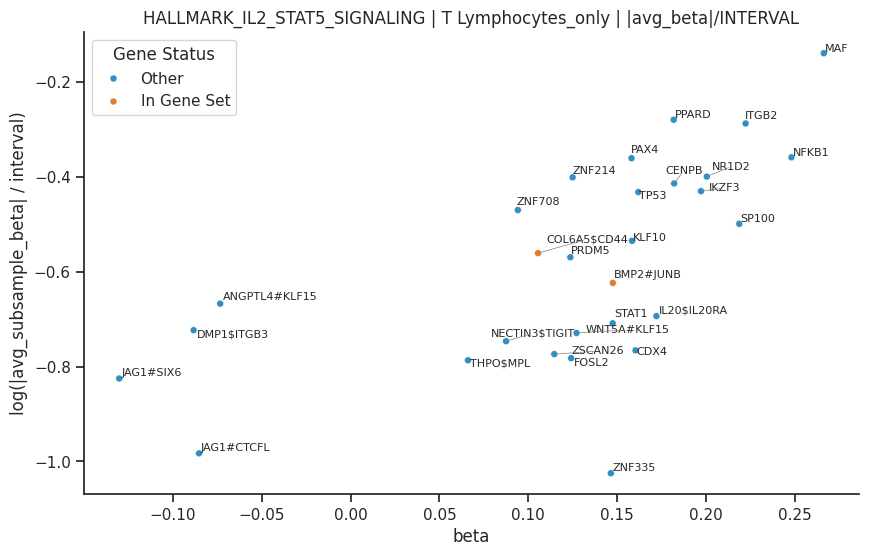

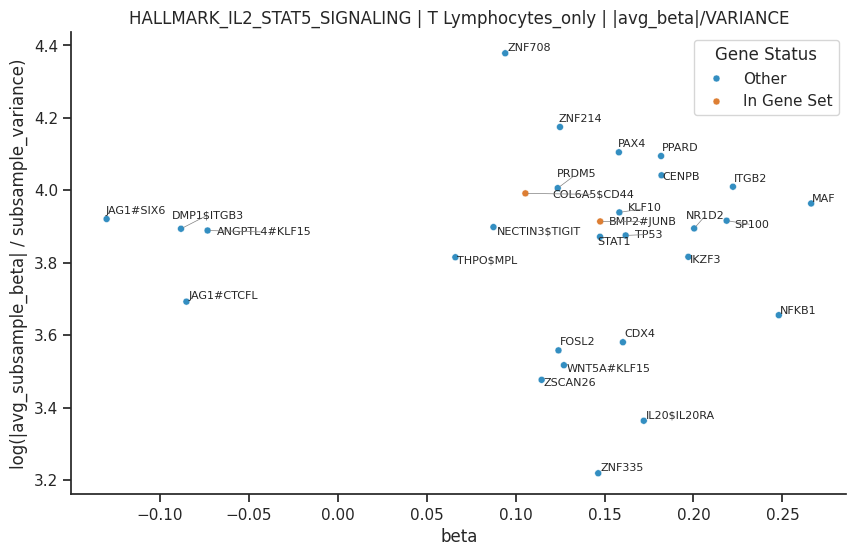

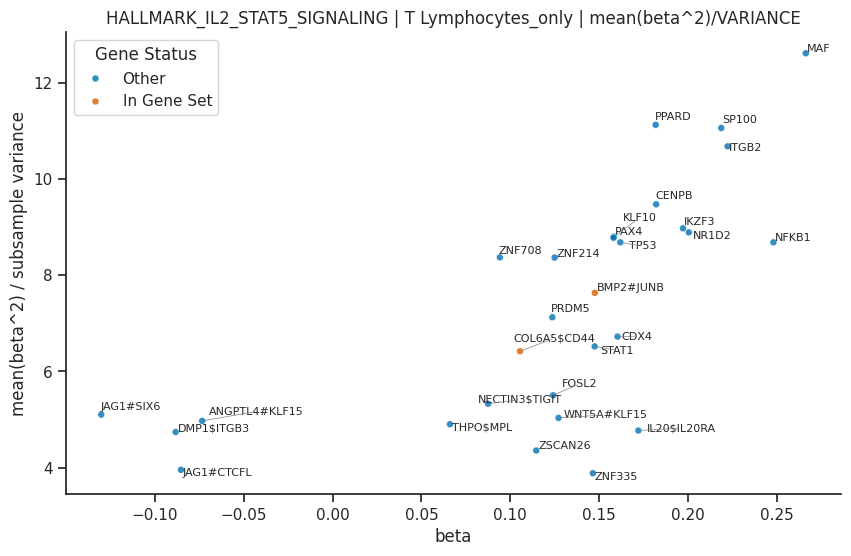

In [10]:
view('HALLMARK_IL2_STAT5_SIGNALING')

### KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY

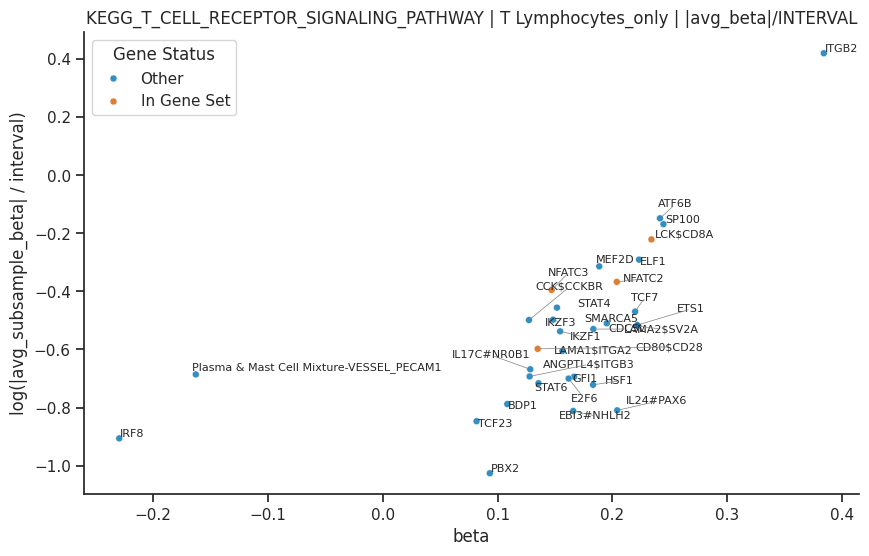

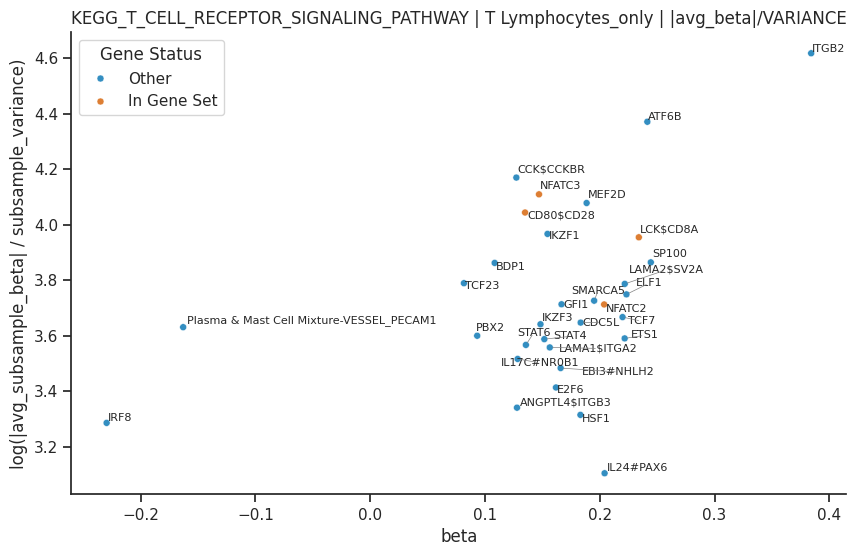

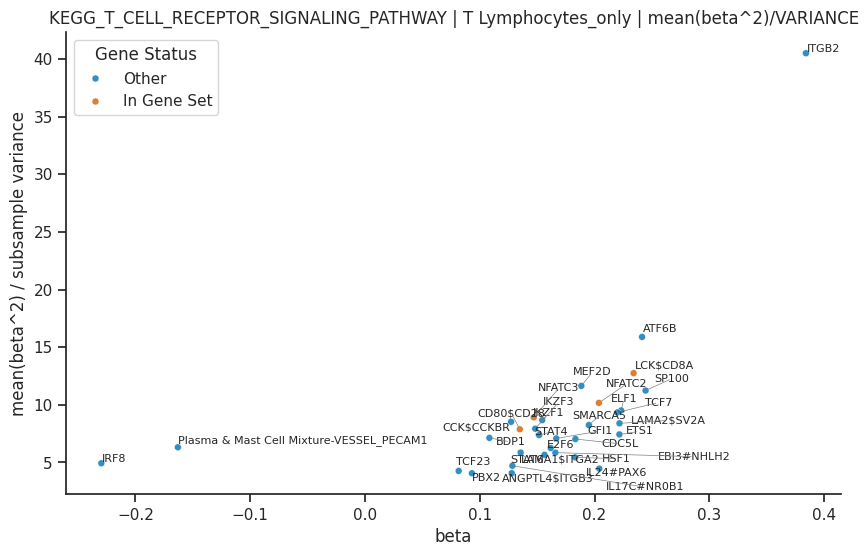

In [11]:
view('KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY')

### GOBP_T_CELL_MEDIATED_CYTOTOXICITY

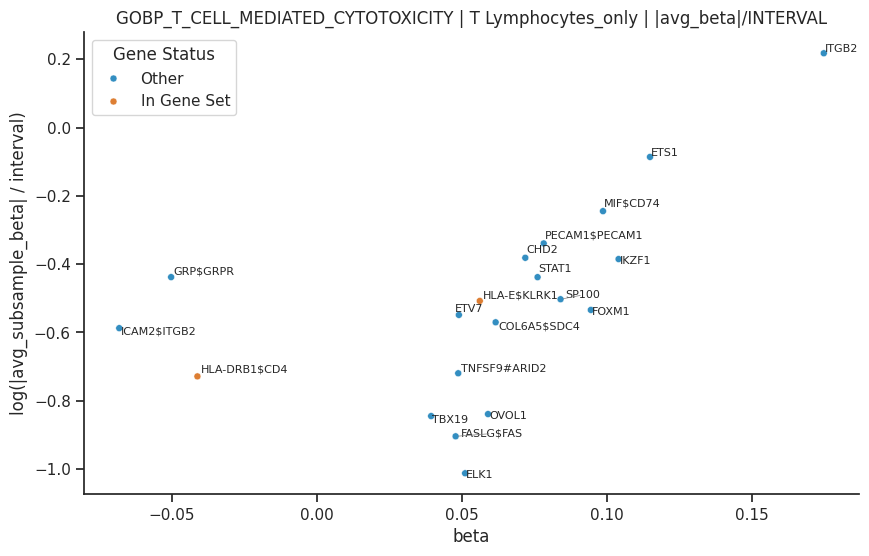

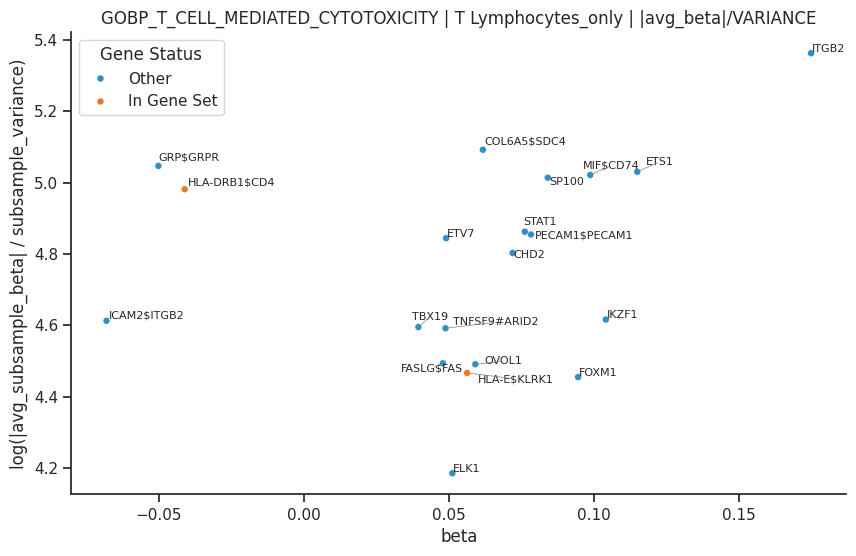

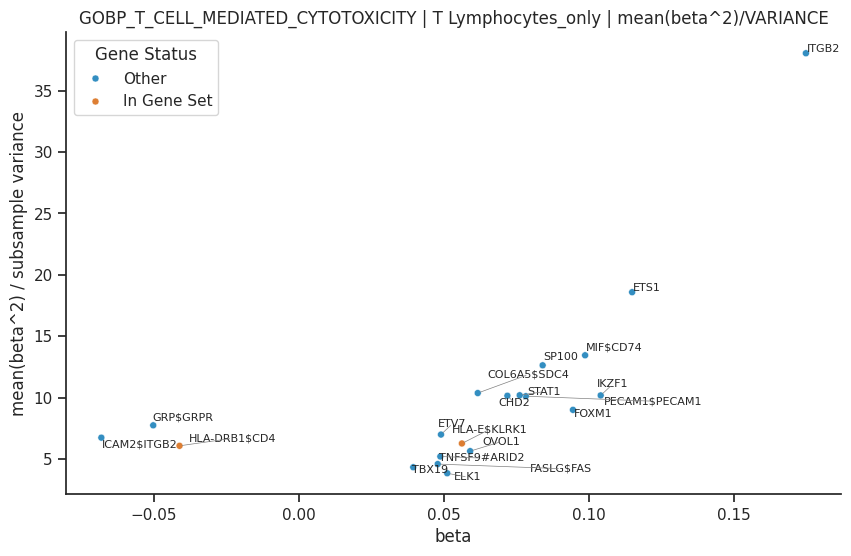

In [12]:
view('GOBP_T_CELL_MEDIATED_CYTOTOXICITY')

### KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY

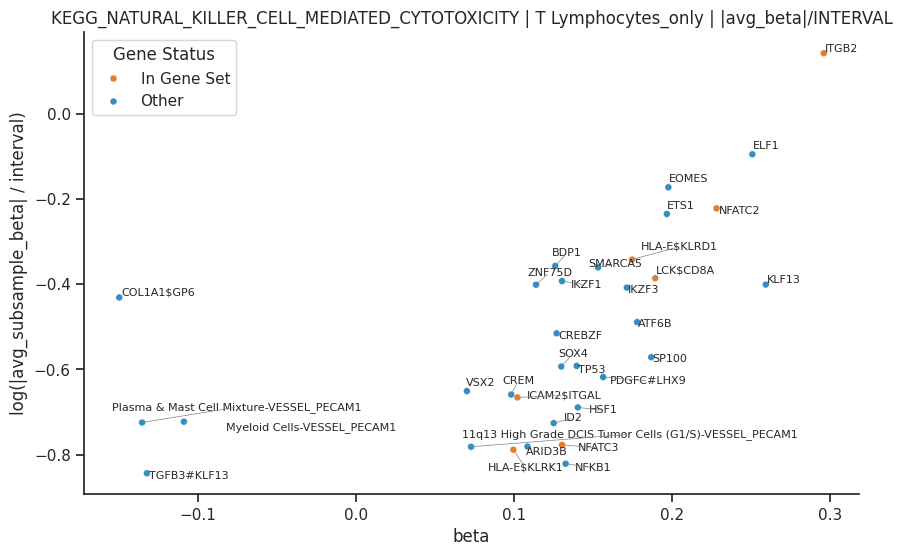

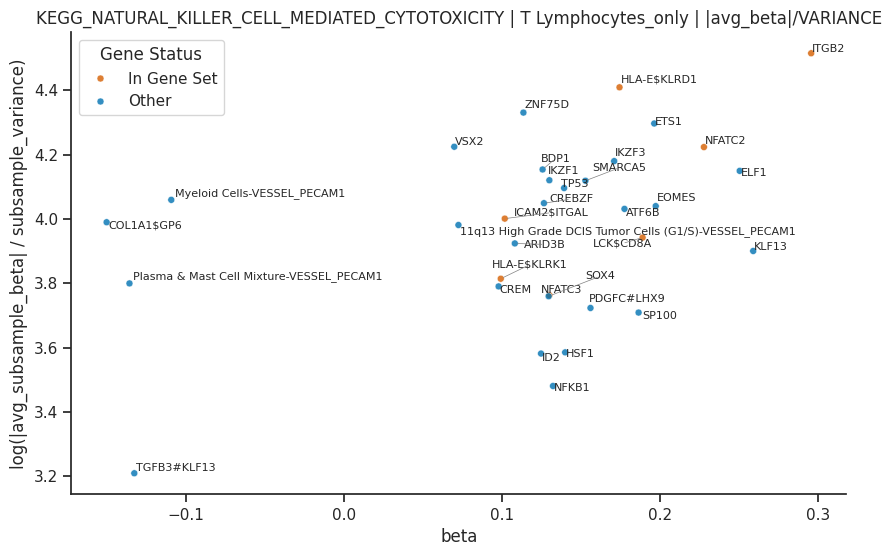

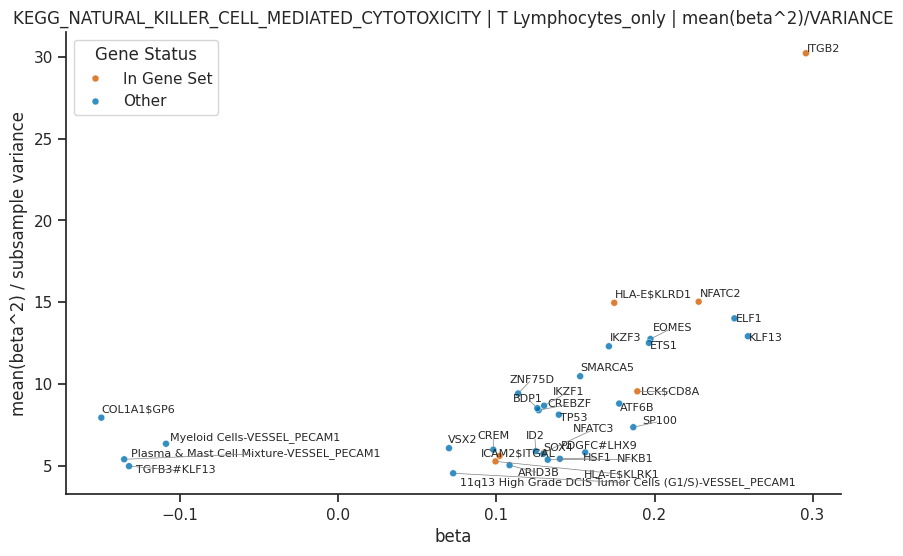

In [13]:
view('KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY')

### HALLMARK_TNFA_SIGNALING_VIA_NFKB

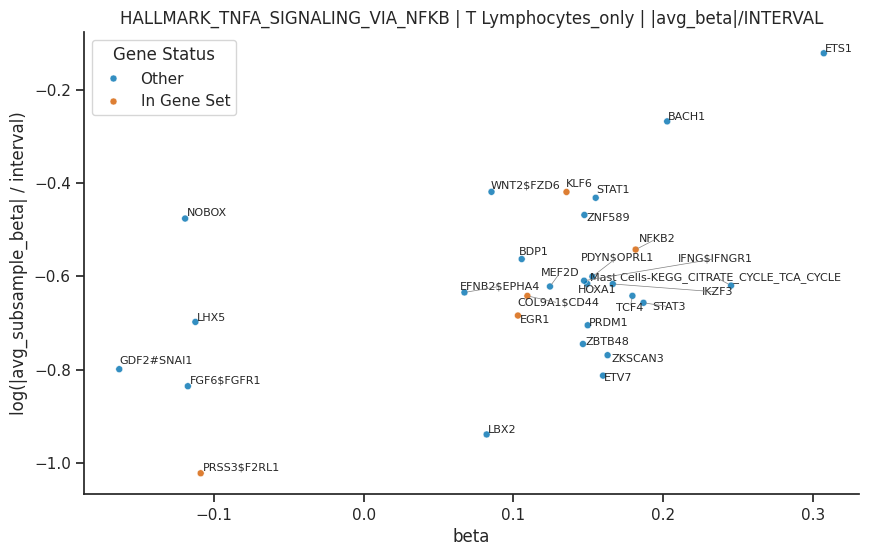

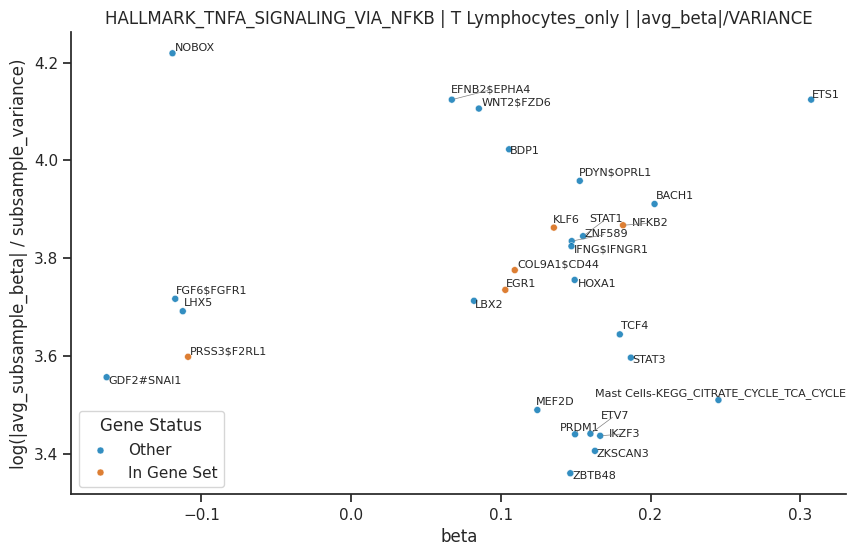

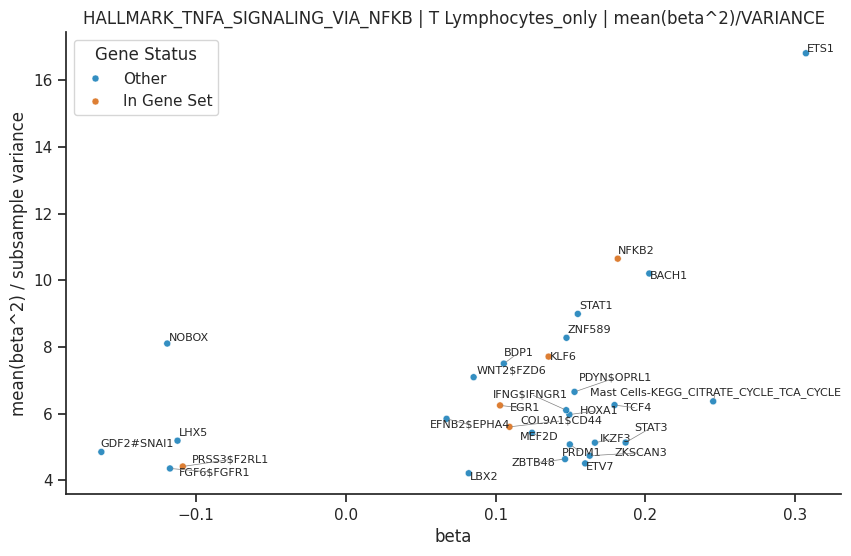

In [14]:
view('HALLMARK_TNFA_SIGNALING_VIA_NFKB')

### HALLMARK_INTERFERON_GAMMA_RESPONSE

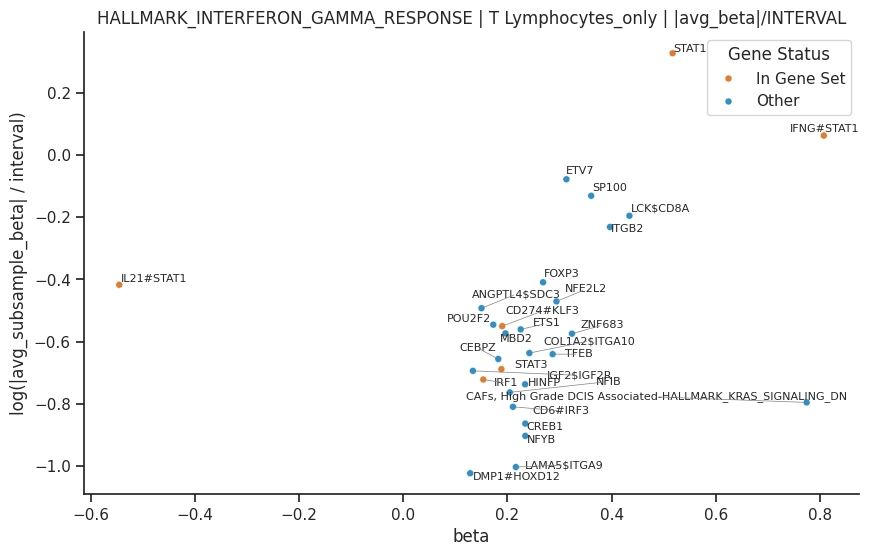

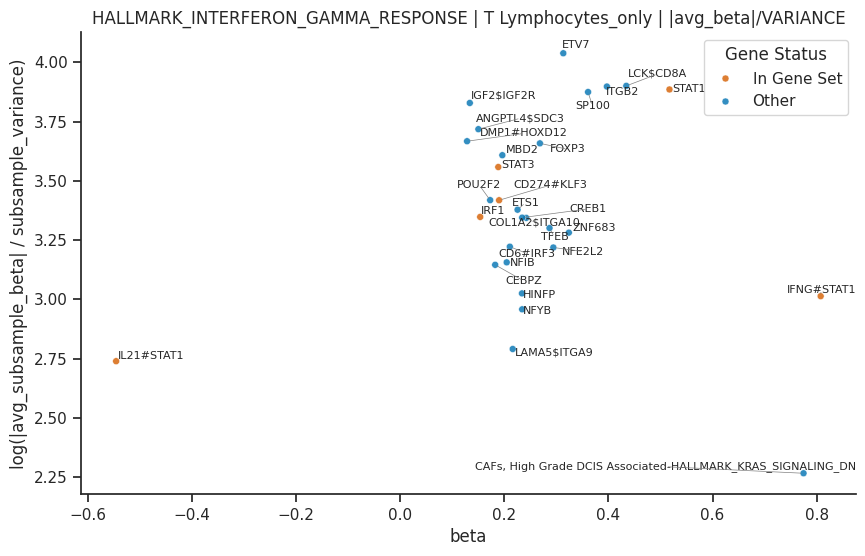

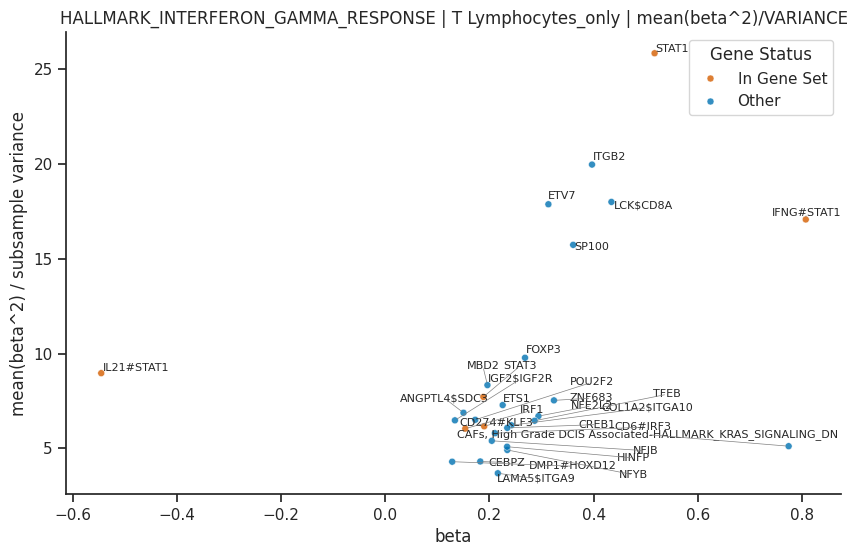

In [15]:
view('HALLMARK_INTERFERON_GAMMA_RESPONSE')

### HALLMARK_INTERFERON_ALPHA_RESPONSE

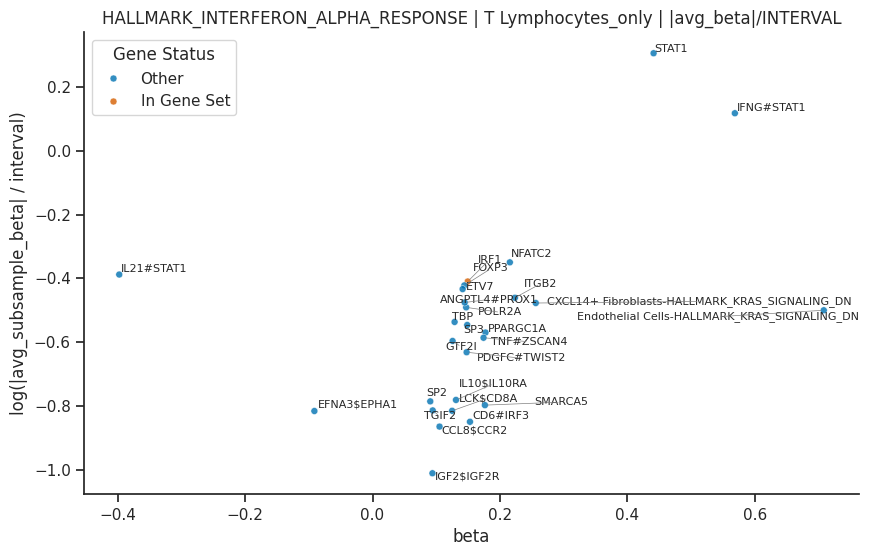

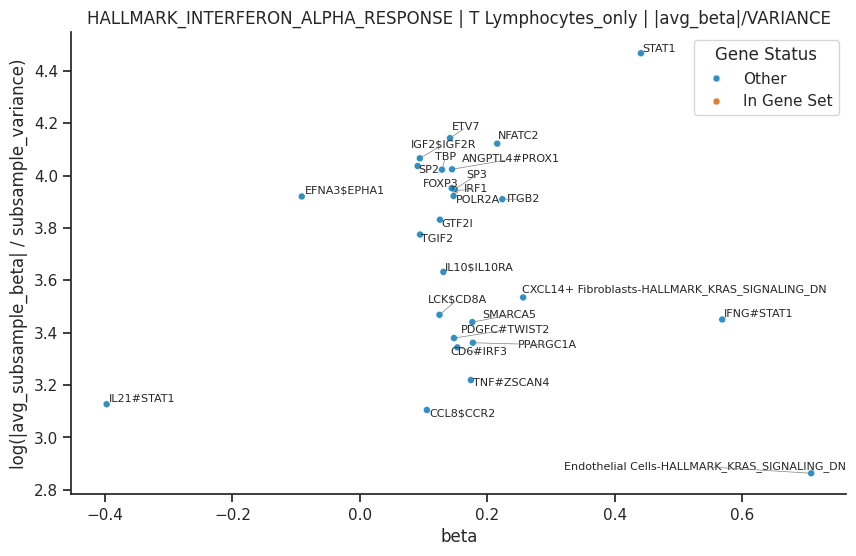

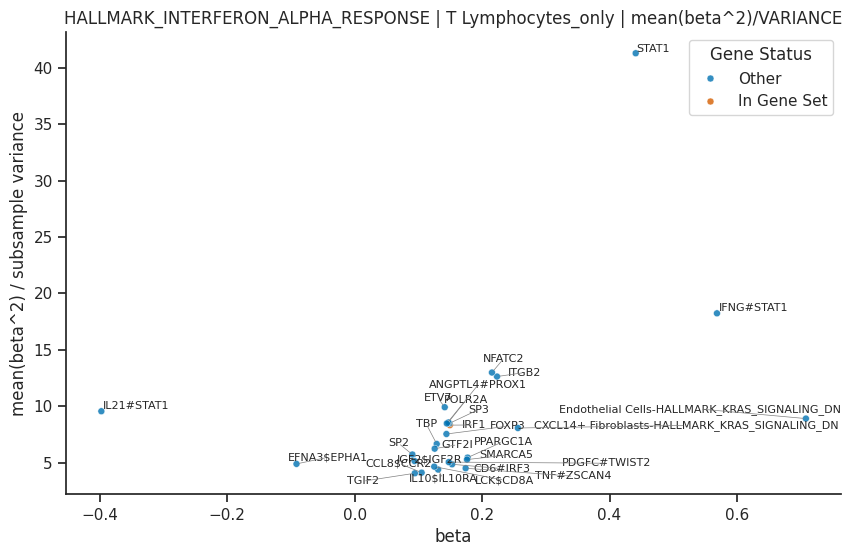

In [16]:
view('HALLMARK_INTERFERON_ALPHA_RESPONSE')

### GOBP_CELL_KILLING

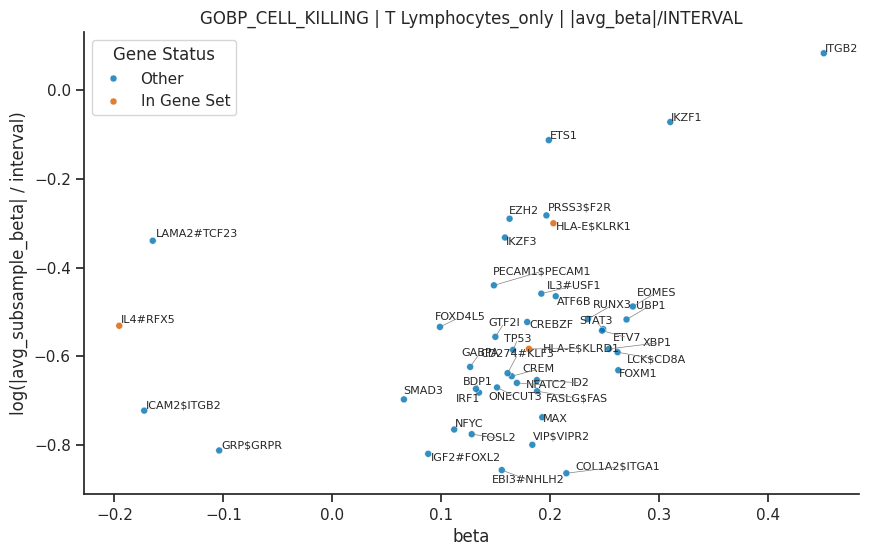

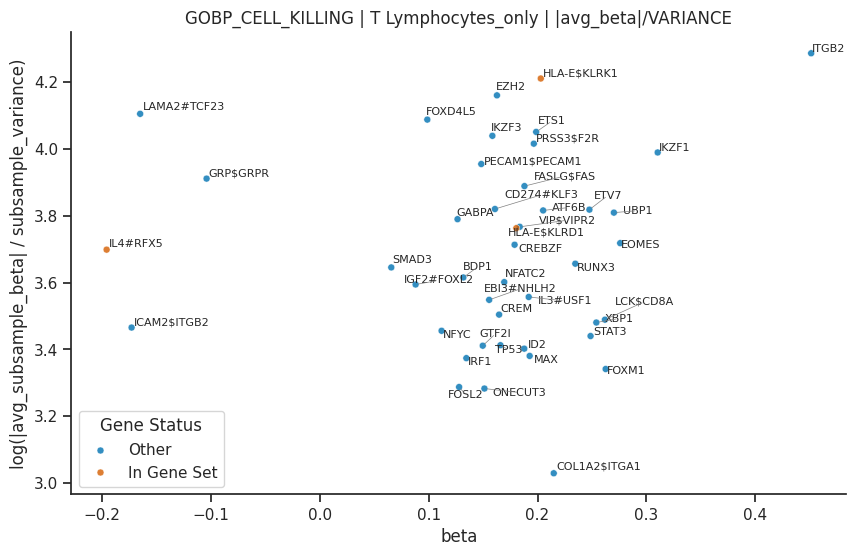

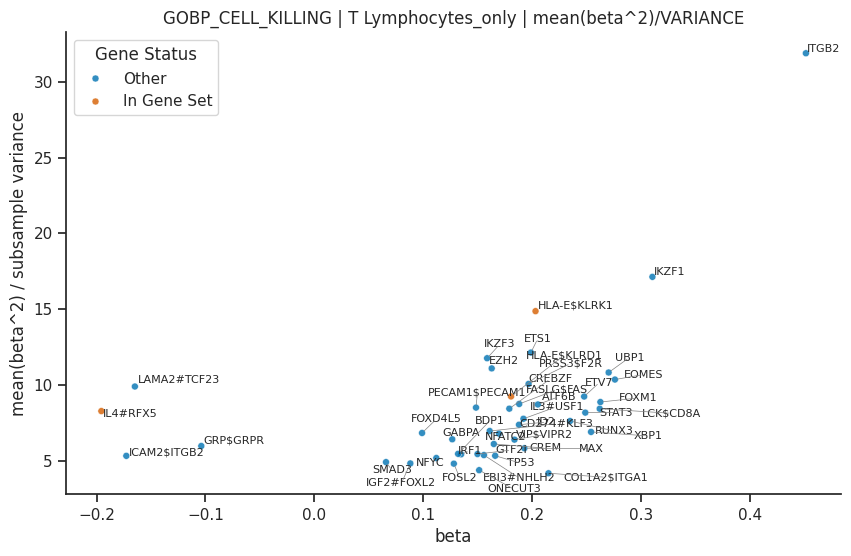

In [17]:
view('GOBP_CELL_KILLING')

### GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY

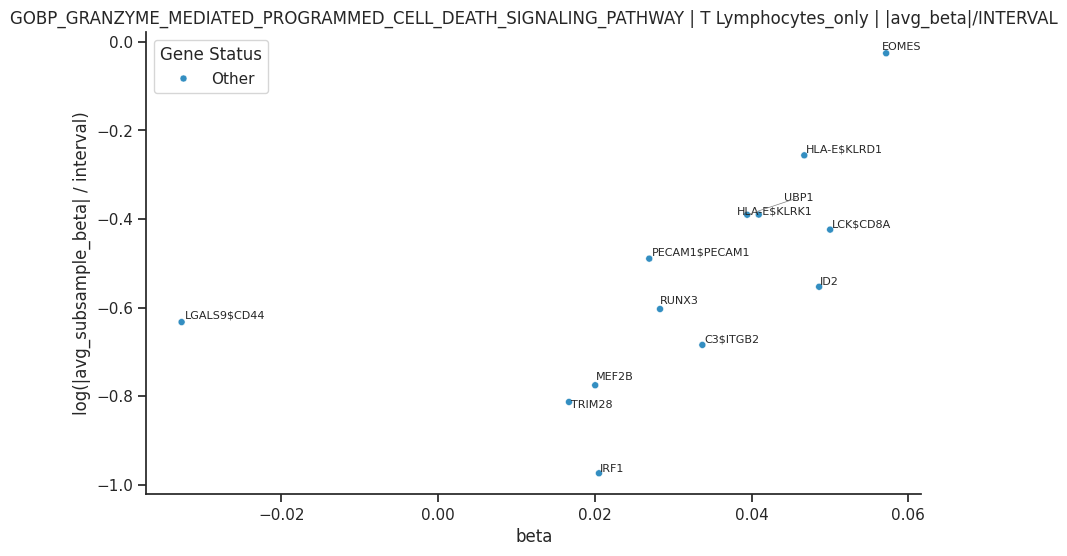

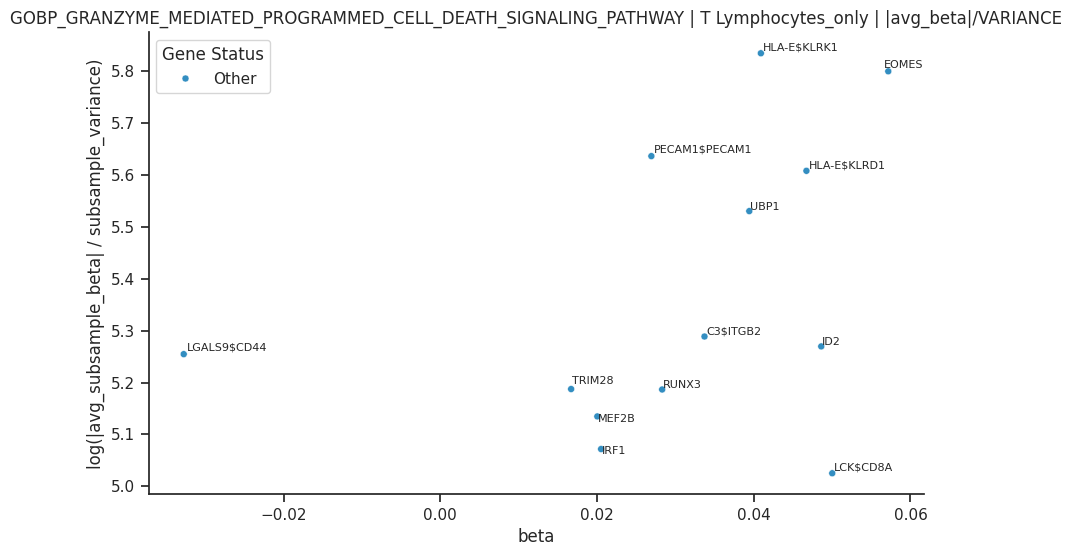

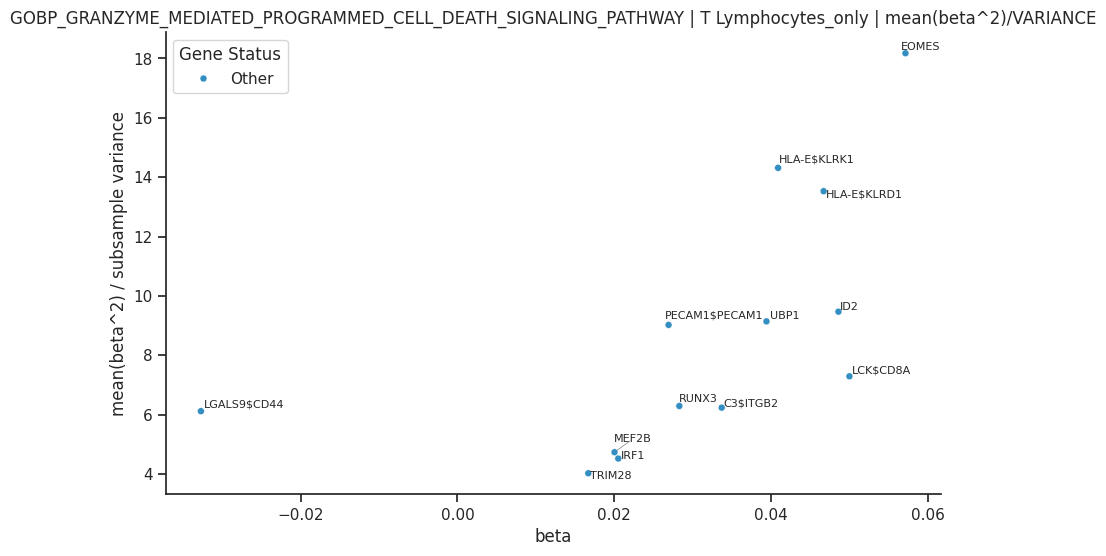

In [18]:
view('GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY')

### GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY

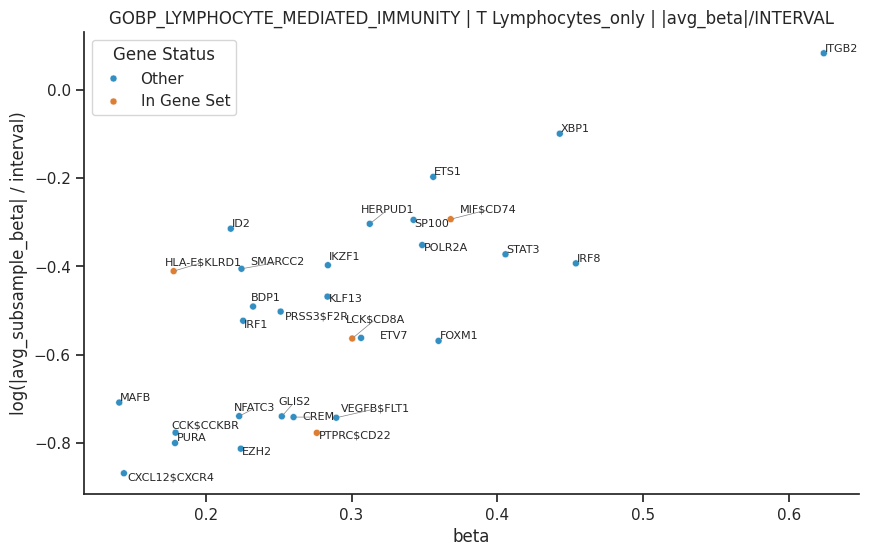

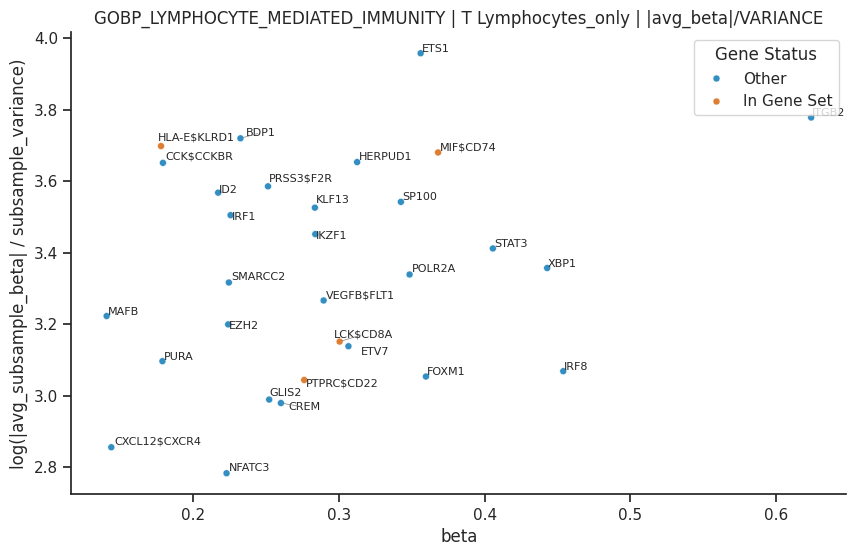

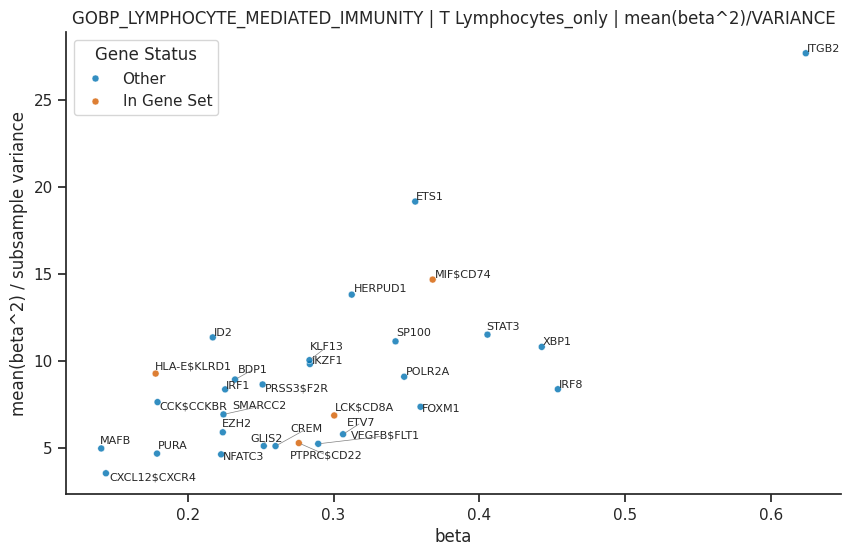

In [19]:
view('GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY')

## Negative controls

### HALLMARK_PANCREAS_BETA_CELLS

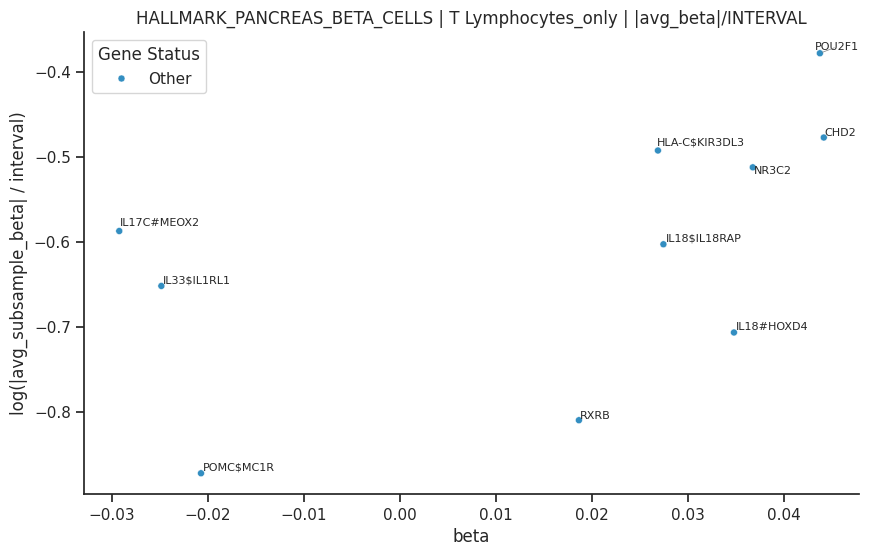

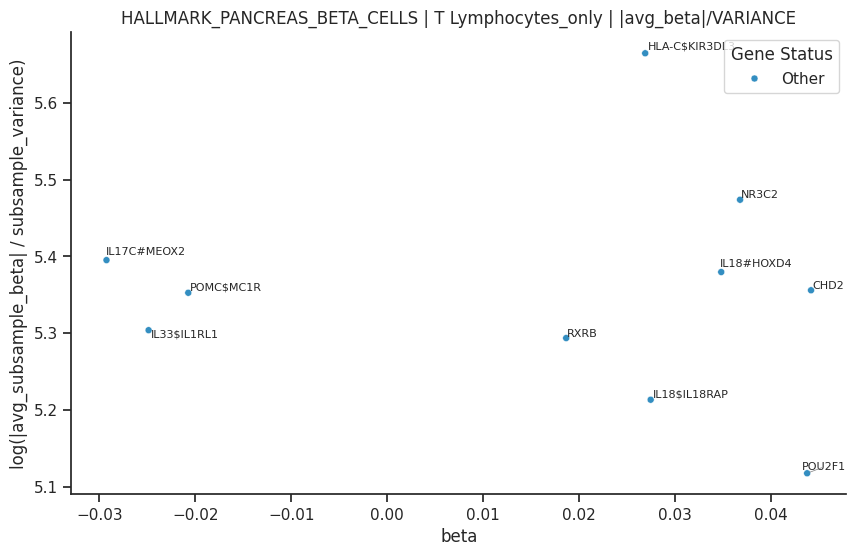

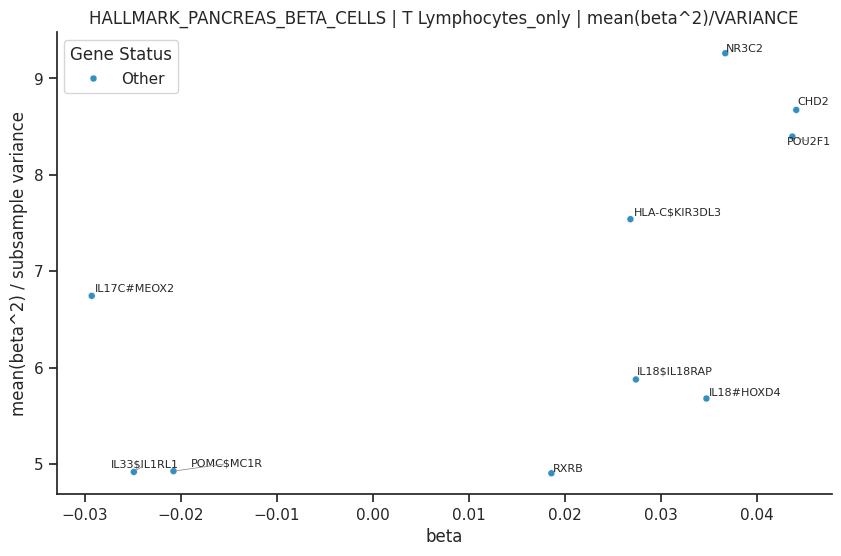

In [20]:
view('HALLMARK_PANCREAS_BETA_CELLS')

### HALLMARK_SPERMATOGENESIS

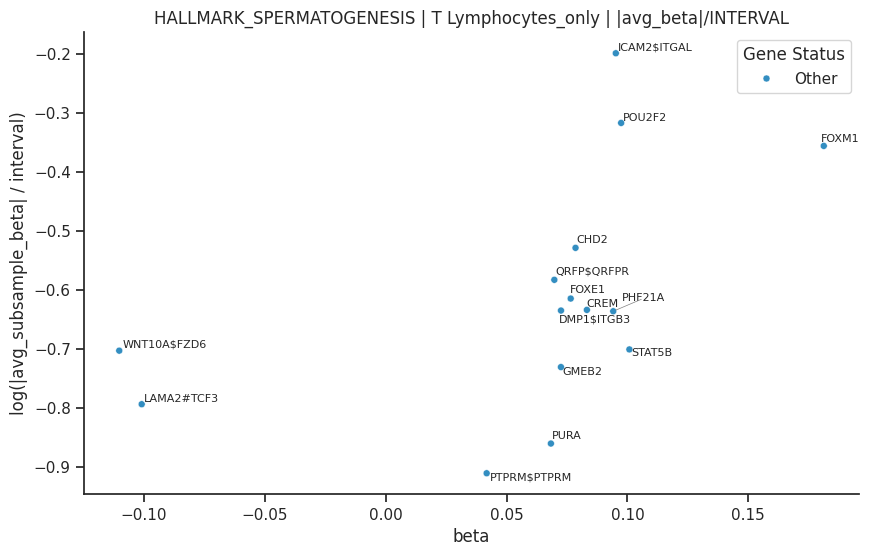

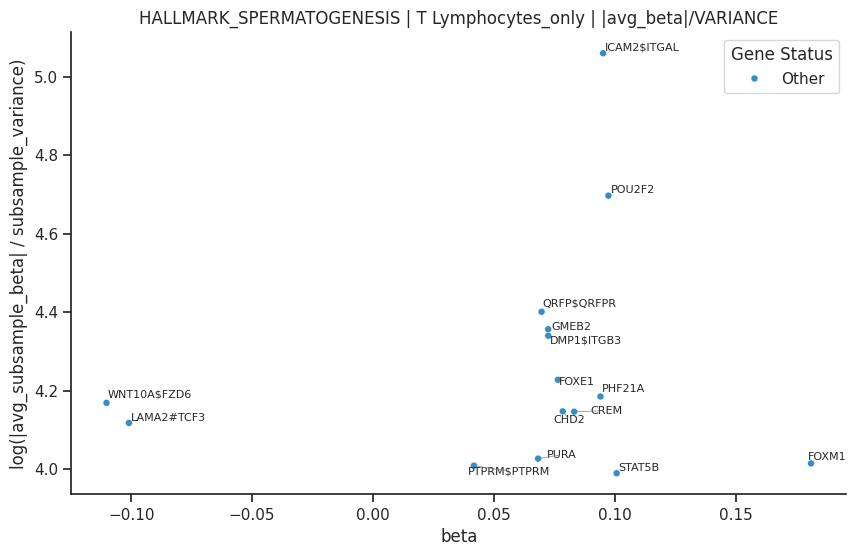

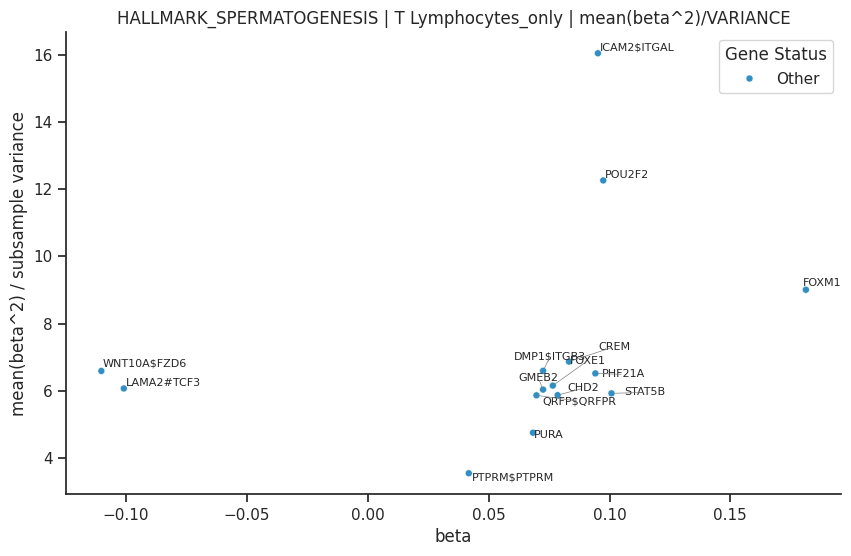

In [21]:
view('HALLMARK_SPERMATOGENESIS')

## MANUAL_ISLET_NEG_CONTROL (manual negative control)

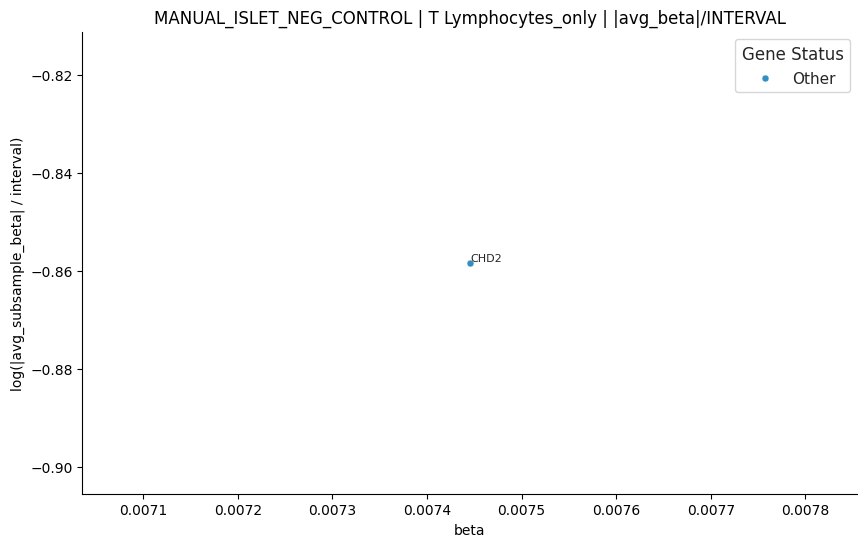

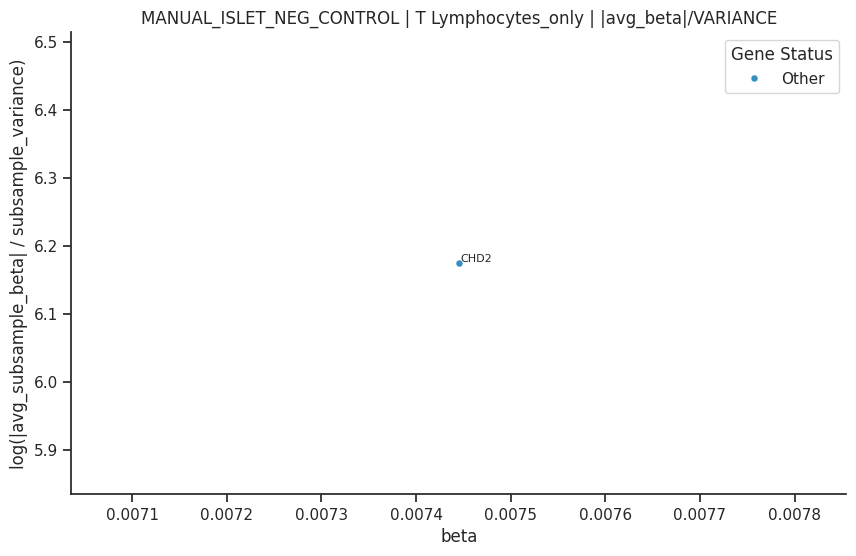

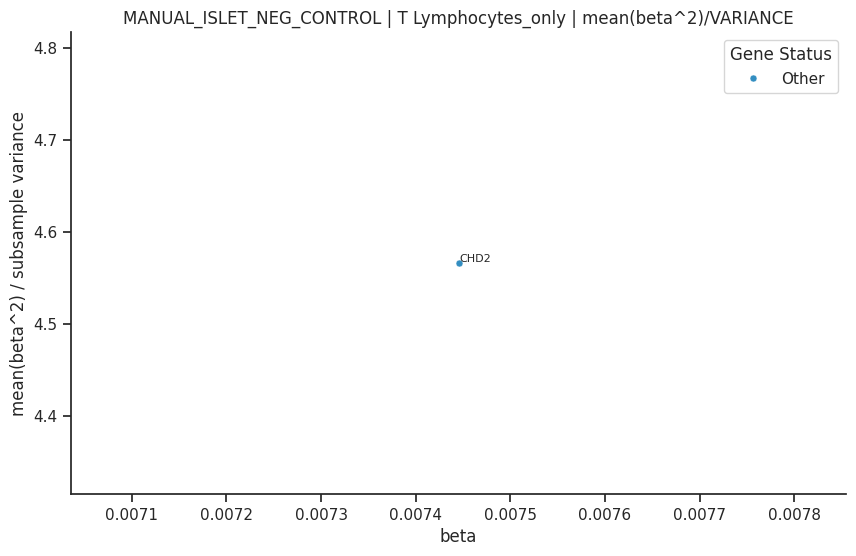

In [5]:
view('MANUAL_ISLET_NEG_CONTROL')

## Spatial gene-set panels

Spatially plot the T cells coloured by their gene-set score (others greyed), then one panel
per **significant `{cell_type}-{gene_set}` neighborhood factor**: the cells of that type
coloured by that gene set's per-cell score (others grey, T cells overlaid in red).

The per-cell-type gene-set scores are **not** cached (only the diffused `{ct}-{SET}` factors
feed the regression), so we recompute them here directly from `normalized_count` -- a plain
sum of the gene set's present genes per cell. (For the diffused factor itself instead, run
`sh.add_cancer_factors(adata, cancer_sets, annot_col=cfg.cell_type_col)` and colour by the
`obsm['x_custom']` column.)

In [ ]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
from metab_processing.LinearRegression.build_x import LAYER, ensure_lognorm_layer

adata = sc.read_h5ad(cfg.adata_path)
ensure_lognorm_layer(adata)
var = set(adata.var_names)
CELL_TYPE_COL = cfg.cell_type_col
TCELL_TYPES = list(cfg.t_cell_types)
# Neighborhood factors {ct}-{SET} come from ALL cell types, not just the T cells.
ALL_CELL_TYPES = None  # set after adata loads (see below)

# Gene sets behind the {ct}-{SET} neighborhood factors (present genes), incl. the vessel marker.
library = sh.load_msigdb(cfg.dbver, cfg.categories)
cancer_sets = {n: [g for g in library.get(n, []) if g in var] for n in cfg.cancer_factors}
cancer_sets.update({v: [g for g in gl if g in var] for v, gl in cfg.vessel.items()})
cancer_sets = {k: v for k, v in cancer_sets.items() if v}
ALL_CELL_TYPES = sorted(adata.obs[CELL_TYPE_COL].astype(str).unique())
print(adata.n_obs, 'cells |', len(cancer_sets), 'cancer gene sets |',
      'cell types:', sorted(adata.obs[CELL_TYPE_COL].astype(str).unique())[:12])

In [ ]:
def gene_set_score(adata, genes):
    """Per-cell sum of a gene set's `normalized_count` expression (present genes only)."""
    present = [g for g in genes if g in adata.var_names]
    if not present:
        return np.zeros(adata.n_obs)
    return adata[:, present].to_df(LAYER)[present].sum(axis=1).to_numpy()


def significant_neighborhood_factors(res, cell_types, sets_dict, touch_zero=True):
    """From a target's `res`, the significant `{ct}-{SET}` neighborhood factors (subsample
    interval excludes 0), ordered by |beta| descending, as (cell_type, set_name, genes)."""
    if res is None or res.empty:
        return []
    sig = sh.filter_nonzero_interval(res, touch_zero=touch_zero).copy()
    sig = sig.reindex(sig['beta'].abs().sort_values(ascending=False).index)
    out = []
    for f in sig['factor']:
        for ct in cell_types:
            for name, genes in sets_dict.items():
                if f == f'{ct}-{name}':
                    out.append((ct, name, genes))
    return out


def plot_spatial_gene_set_panels(adata, cell_type_col, tcell_types, tcell_genes, panels,
                                 point_size=3, overlay_tcells=True, cmap='viridis',
                                 tcell_label='T cells'):
    """Row of spatial panels: panel 0 = T cells coloured by `tcell_genes` score (others grey);
    then one panel per (cell_type, set_name, genes) in `panels` = those cells coloured by the
    set score (others grey), T cells overlaid in red. Returns the figure."""
    xy = np.asarray(adata.obsm['spatial'])
    ct = adata.obs[cell_type_col].astype(str).to_numpy()
    tmask = np.isin(ct, [str(t) for t in tcell_types])

    def _panel(ax, mask, values, title):
        ax.scatter(xy[~mask, 0], xy[~mask, 1], s=point_size * 0.5, c='lightgrey', linewidths=0)
        vmax = float(np.nanpercentile(values[mask], 95)) if mask.sum() else None  # cap display at p95
        sc_ = ax.scatter(xy[mask, 0], xy[mask, 1], s=point_size, c=values[mask], cmap=cmap,
                         vmax=vmax, linewidths=0)
        plt.colorbar(sc_, ax=ax, shrink=0.7)
        ax.set_title(title, fontsize=9); ax.set_aspect('equal')
        ax.set_xticks([]); ax.set_yticks([])

    n = 1 + len(panels)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 5), squeeze=False)
    axes = axes[0]
    _panel(axes[0], tmask, gene_set_score(adata, tcell_genes), f'{tcell_label}: target gene-set score')
    for ax, (pct, name, genes) in zip(axes[1:], panels):
        _panel(ax, ct == pct, gene_set_score(adata, genes), f'{pct}\n{name}')
        if overlay_tcells:
            ax.scatter(xy[tmask, 0], xy[tmask, 1], s=point_size, c='red', linewidths=0)
    fig.tight_layout()
    return fig

## Example -- pick a target signature, show its significant neighborhood sources

In [ ]:
SIG = 'HALLMARK_INTERFERON_GAMMA_RESPONSE'      # <- any target in TARGETS
LABEL = sb.runspecs(cfg)[0]['label']            # breast has one T type -> 'T Lymphocytes_only'

res = sb.load_res(cfg, SIG, LABEL)
panels = significant_neighborhood_factors(res, ALL_CELL_TYPES, cancer_sets)
print(f'{SIG} | {LABEL}: {len(panels)} significant {{ct}}-{{set}} neighborhood factors')

# genes actually scored for the signature (after factor removal), else its present genes
m = membership.get(SIG, {})
tcell_genes = m.get('remaining') or m.get('present', [])

if res is not None:
    plot_spatial_gene_set_panels(adata, CELL_TYPE_COL, TCELL_TYPES, tcell_genes,
                                 panels[:8]);     # cap panels for a readable row

## Spatial panels for every target

In [ ]:
def spatial_view(sig, top=8):
    label = sb.runspecs(cfg)[0]['label']           # breast: single T type -> '<ct>_only'
    res = sb.load_res(cfg, sig, label)
    if res is None:
        print('not yet computed:', sig); return
    panels = significant_neighborhood_factors(res, ALL_CELL_TYPES, cancer_sets)
    m = membership.get(sig, {})
    tcell_genes = m.get('remaining') or m.get('present', [])
    print(f'{sig}: {len(panels)} significant {{ct}}-{{set}} neighborhood factors')
    fig = plot_spatial_gene_set_panels(adata, CELL_TYPE_COL, TCELL_TYPES, tcell_genes, panels[:top])
    fig.suptitle(sig, y=1.02)


for sig in TARGETS:
    spatial_view(sig)